# Mapping Public Attitudes toward E-Agriculture in Global Twitter Discourse — replication

Boshnjaku, A., Plasari, E. and Fata, I.

This notebook reproduces the paper's tables and figures from the public files in `data/` and `results/`.

| Section | Reproduces | Needs tweet text? |
|---|---|---|
| 2 | Table 1 | no |
| 3 | Tables 2, 3, 4 | no |
| 4 | Tables 5, 6, 7, 9 | no |
| 5 | Table 10, Figures 2–4 | no |
| 6 | Tables 11, 12 | no |
| 7 | Tables 15, 16 | no |
| 8 | Table 14 | no |
| 9 | Table 13, Figure 5 (stored results) | no |
| 10 | LDA refit, coherence sweep, stability | **yes** — optional |
| 11 | Re-scoring with TextBlob, VADER, Twitter-RoBERTa | **yes** — optional |

Tweet text is not redistributed, in line with the X (Twitter) developer terms. To run sections 10–11, rehydrate the
IDs in `data/tweets_labels.csv` and save `data/rehydrated_text.csv` with columns `tweet_id,text`.
Tweets deleted since collection cannot be recovered, so refitted results may differ slightly.

Regenerated figures are written to `results/figures/`; the published figures are in `figures/`.

**Colab:** run `!git clone https://github.com/Endriplasari/eagriculture-twitter-sentiment.git` and `%cd eagriculture-twitter-sentiment/notebooks` first.

## 1. Setup and data

In [1]:
import os, re, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.stats import chi2, binomtest
warnings.filterwarnings("ignore")

ROOT = next(p for p in [".", ".."] if os.path.isdir(os.path.join(p, "data")))
DATA, RESULTS = os.path.join(ROOT, "data"), os.path.join(ROOT, "results")
FIGS = os.path.join(RESULTS, "figures")          # regenerated figures; the paper's originals are in figures/
os.makedirs(FIGS, exist_ok=True)

ORDER = ["positive", "neutral", "negative"]
MODELS = {"textblob_sentiment": "TextBlob", "vader_sentiment": "VADER", "roberta_sentiment": "Twitter-RoBERTa"}
TRANSFORMER = "cardiffnlp/twitter-roberta-base-sentiment"   # 3-class model used in the paper
CONF_THRESHOLD = 0.6

tweets = pd.read_csv(os.path.join(DATA, "tweets_labels.csv"), dtype={"tweet_id": str})
gold = pd.read_csv(os.path.join(DATA, "gold_standard.csv"), dtype={"tweet_id": str})
tweets["created_at"] = pd.to_datetime(tweets["created_at"], utc=True)

assert len(tweets) == 10009 and tweets["tweet_id"].is_unique
assert len(gold) == 600 and gold["gold_label"].notna().all()
print(f"corpus: {len(tweets):,} tweets, {tweets.created_at.min():%d %b %Y} to {tweets.created_at.max():%d %b %Y}")
print("tweets without a transformer label:", tweets.roberta_sentiment.isna().sum())
print("evaluation set:", len(gold), "| with transformer label:", gold.roberta_sentiment.notna().sum())
TABLES = {}

corpus: 10,009 tweets, 08 Jul 2024 to 26 Dec 2024
tweets without a transformer label: 8
evaluation set: 600 | with transformer label: 599


## 2. Table 1 — corpus sentiment distribution

Eight tweets have no transformer label (the scoring call failed on them), so the transformer column is computed
over the 10,001 labelled tweets.

In [2]:
t1 = pd.DataFrame({name: tweets[col].value_counts(normalize=True).reindex(ORDER).mul(100).round(2)
                   for col, name in MODELS.items()})
t1.index.name = "Sentiment"
print("denominators:", {name: int(tweets[col].notna().sum()) for col, name in MODELS.items()})
TABLES["Table 1"] = t1
t1

denominators: {'TextBlob': 10009, 'VADER': 10009, 'Twitter-RoBERTa': 10001}


,TextBlob,VADER,Twitter-RoBERTa
Sentiment,,,
positive,75.48,88.66,63.92
neutral,19.52,7.82,33.97
negative,5.00,3.52,2.11


## 3. Tables 2–4 — accuracy, confusion matrix, McNemar's test

One evaluation tweet has no transformer label; transformer-based metrics use the remaining 599.
The majority-vote ensemble resolves three-way ties in favour of the transformer, the primary classifier,
so the result is identical on every run.

In [3]:
ev = gold.dropna(subset=["roberta_sentiment"]).copy()

def majority_vote(row):
    votes = [row.textblob_sentiment, row.vader_sentiment, row.roberta_sentiment]
    for label in votes:
        if votes.count(label) >= 2:
            return label
    return row.roberta_sentiment            # all three disagree -> primary classifier

ev["ensemble"] = ev.apply(majority_vote, axis=1)
t2 = pd.DataFrame([
    ("TextBlob", accuracy_score(gold.gold_label, gold.textblob_sentiment), len(gold)),
    ("VADER", accuracy_score(gold.gold_label, gold.vader_sentiment), len(gold)),
    ("Transformer-based (RoBERTa)", accuracy_score(ev.gold_label, ev.roberta_sentiment), len(ev)),
    ("Ensemble (majority vote)", accuracy_score(ev.gold_label, ev.ensemble), len(ev)),
], columns=["Model", "Accuracy", "n"]).round({"Accuracy": 3})
print("three-way ties resolved to the transformer:",
      int((ev[list(MODELS)].nunique(axis=1) == 3).sum()))
print("gold labels:", gold.gold_label.value_counts().to_dict())
TABLES["Table 2"] = t2
t2

three-way ties resolved to the transformer: 14
gold labels: {'positive': 322, 'neutral': 263, 'negative': 15}


,Model,Accuracy,n
0,TextBlob,0.560,600
1,VADER,0.578,600
2,Transformer-based (RoBERTa),0.783,599
3,Ensemble (majority vote),0.628,599


In [4]:
t3 = pd.DataFrame(confusion_matrix(ev.gold_label, ev.roberta_sentiment, labels=ORDER),
                  index=[f"Gold: {l}" for l in ORDER], columns=[f"Pred: {l}" for l in ORDER])
TABLES["Table 3"] = t3
t3

,Pred: positive,Pred: neutral,Pred: negative
Gold: positive,287,34,0
Gold: neutral,84,172,7
Gold: negative,0,5,10


In [5]:
right_r = ev.roberta_sentiment == ev.gold_label
right_v = ev.vader_sentiment == ev.gold_label
b, c = int((right_r & ~right_v).sum()), int((~right_r & right_v).sum())
stat = (abs(b - c) - 1) ** 2 / (b + c)               # continuity-corrected McNemar chi-squared, 1 df
t4 = pd.DataFrame([{"Model comparison": "Transformer vs. VADER", "Discordant pairs (b / c)": f"{b} / {c}",
                    "chi-squared (1 df, corrected)": round(stat, 2), "p-value": f"{chi2.sf(stat, 1):.2e}"}])
print(f"exact binomial p = {binomtest(min(b, c), b + c, 0.5).pvalue:.2e}")
TABLES["Table 4"] = t4
t4

exact binomial p = 7.29e-20


,Model comparison,Discordant pairs (b / c),"chi-squared (1 df, corrected)",p-value
0,Transformer vs. VADER,158 / 35,77.12,1.61e-18


## 4. Tables 5, 6, 7, 9 — confidence and disagreement

In [6]:
conf = ev.roberta_confidence
t5 = conf.describe().round(3).to_frame("Value")
t5.index = ["Count", "Mean", "Standard deviation", "Minimum", "25th percentile", "Median", "75th percentile", "Maximum"]
TABLES["Table 5"] = t5

t6 = pd.DataFrame([(f"< {th}", int((conf < th).sum()),
                    round(accuracy_score(ev.gold_label[conf < th], ev.roberta_sentiment[conf < th]), 3))
                   for th in (0.5, CONF_THRESHOLD)], columns=["Confidence threshold", "Tweets (N)", "Accuracy"])
TABLES["Table 6"] = t6

def disagreement(a, b):
    d = gold.dropna(subset=[a, b])
    return round((d[a] != d[b]).mean(), 3), len(d)
pairs = [("textblob_sentiment", "vader_sentiment"), ("textblob_sentiment", "roberta_sentiment"),
         ("vader_sentiment", "roberta_sentiment")]
t7 = pd.DataFrame([(f"{MODELS[a]} vs. {MODELS[b]}", *disagreement(a, b)) for a, b in pairs],
                  columns=["Model pair", "Disagreement rate", "n"])
TABLES["Table 7"] = t7

t9 = ev.groupby("roberta_sentiment").roberta_confidence.mean().reindex(ORDER).round(3).to_frame("Mean confidence")
TABLES["Table 9"] = t9
display(t5, t6, t7, t9)

,Value
Count,599.000
Mean,0.739
Standard deviation,0.137
Minimum,0.453
25th percentile,0.621
Median,0.750
75th percentile,0.853
Maximum,0.991


,Confidence threshold,Tweets (N),Accuracy
0,< 0.5,13,0.769
1,< 0.6,124,0.669


,Model pair,Disagreement rate,n
0,TextBlob vs. VADER,0.212,600
1,TextBlob vs. Twitter-RoBERTa,0.389,599
2,VADER vs. Twitter-RoBERTa,0.331,599


,Mean confidence
roberta_sentiment,
positive,0.766
neutral,0.696
negative,0.666


## 5. Table 10 and Figures 2–4 — monthly sentiment

The collection window runs from 8 July to 26 December 2024, so July and December are partial months.

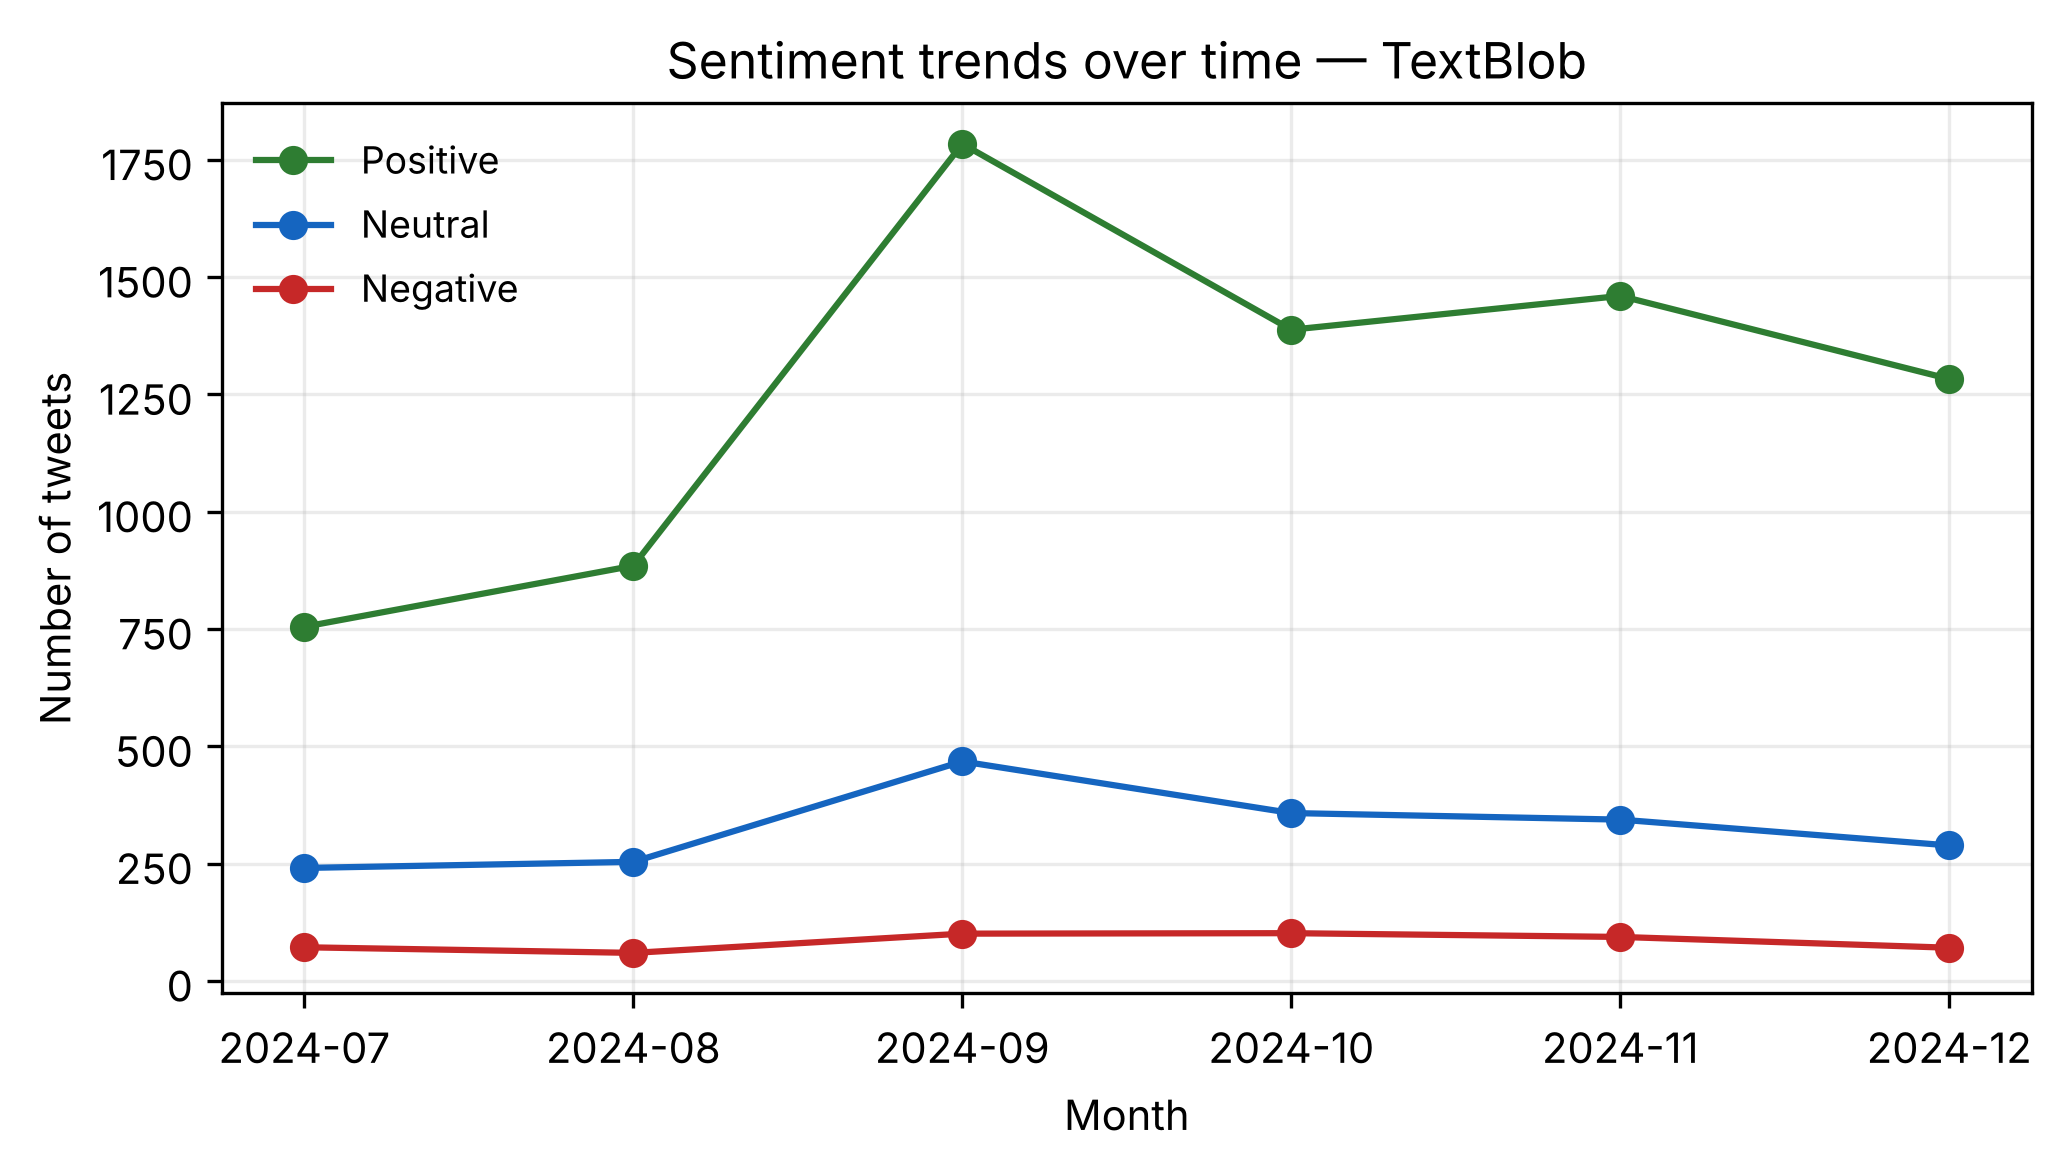

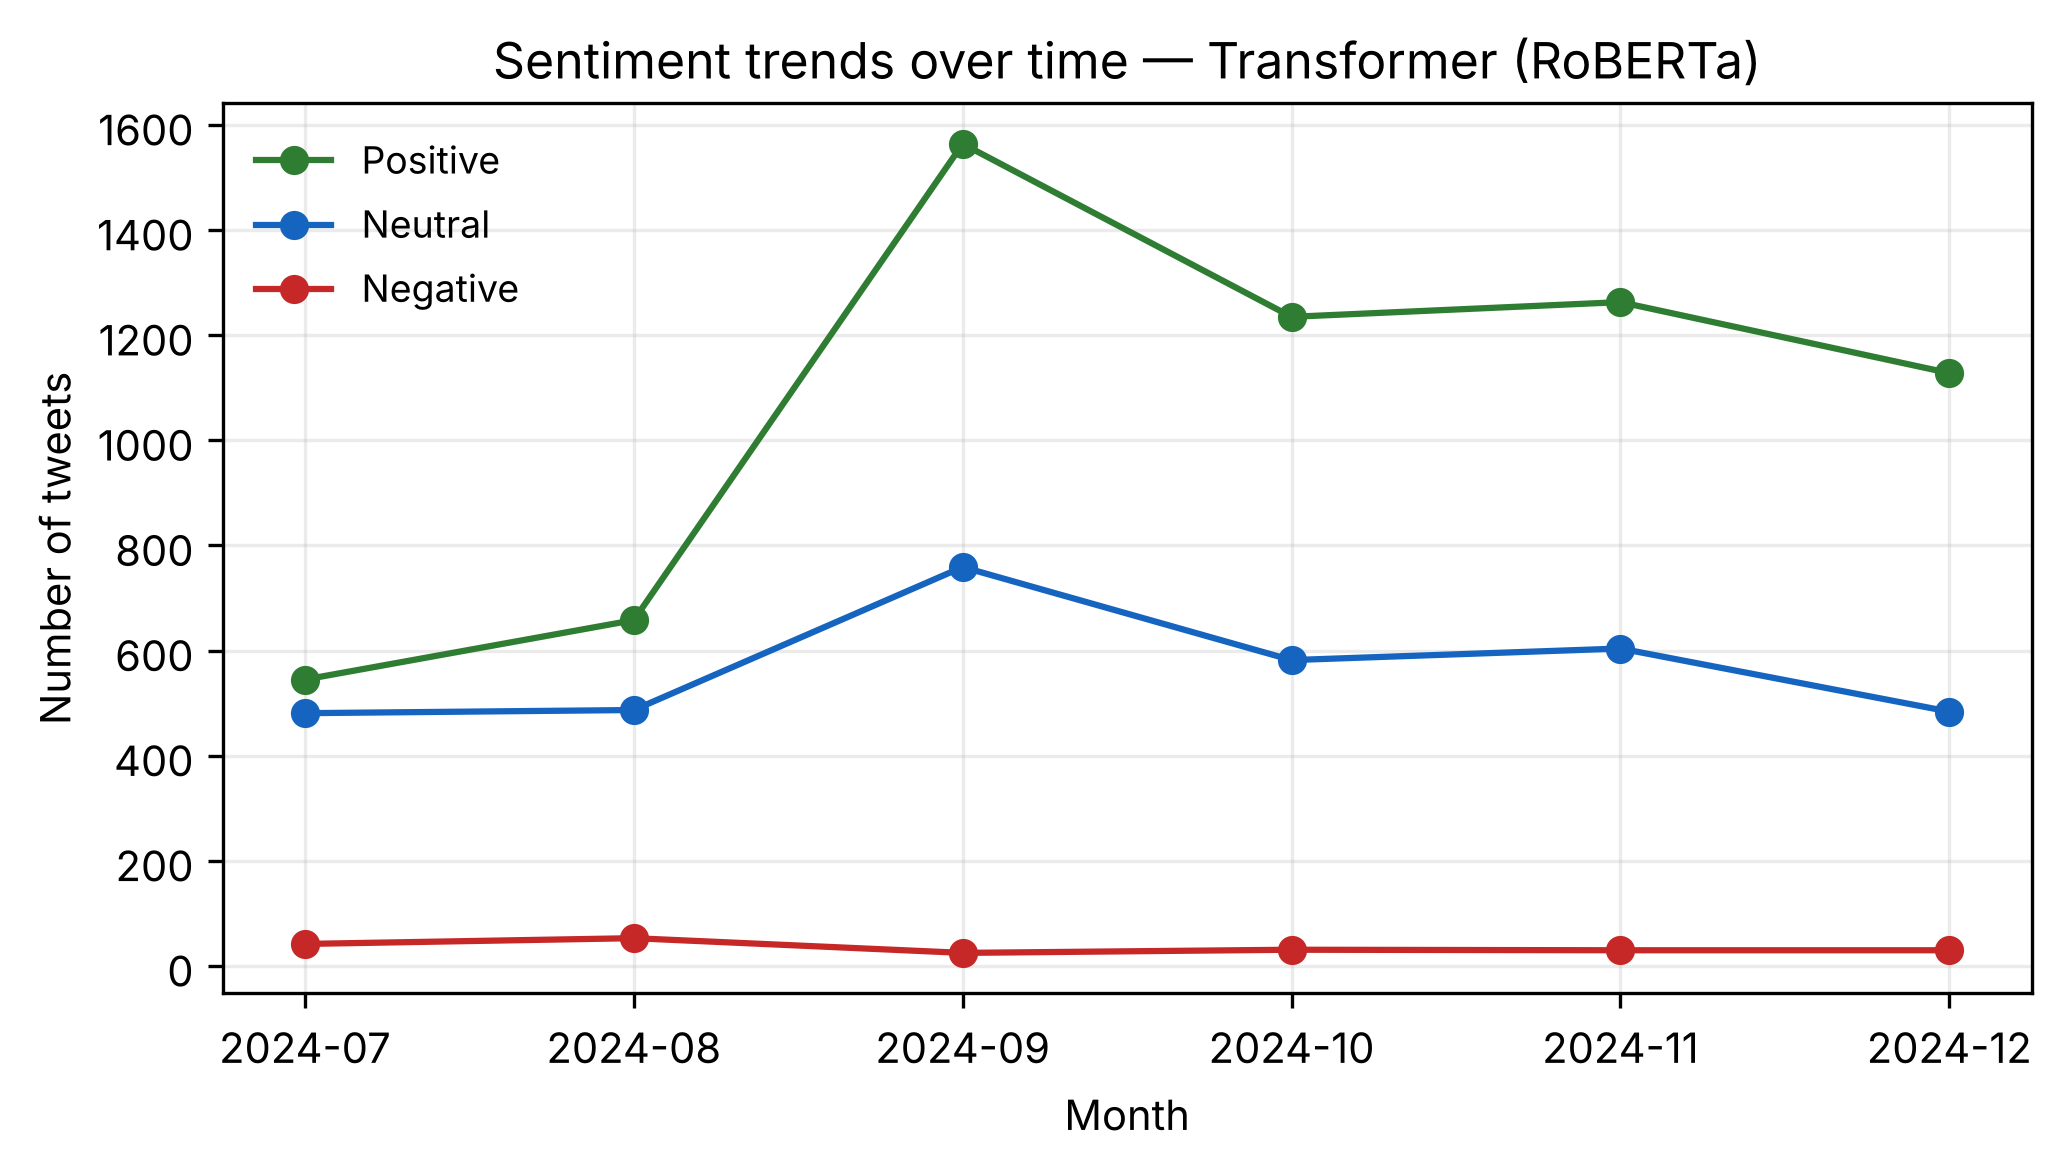

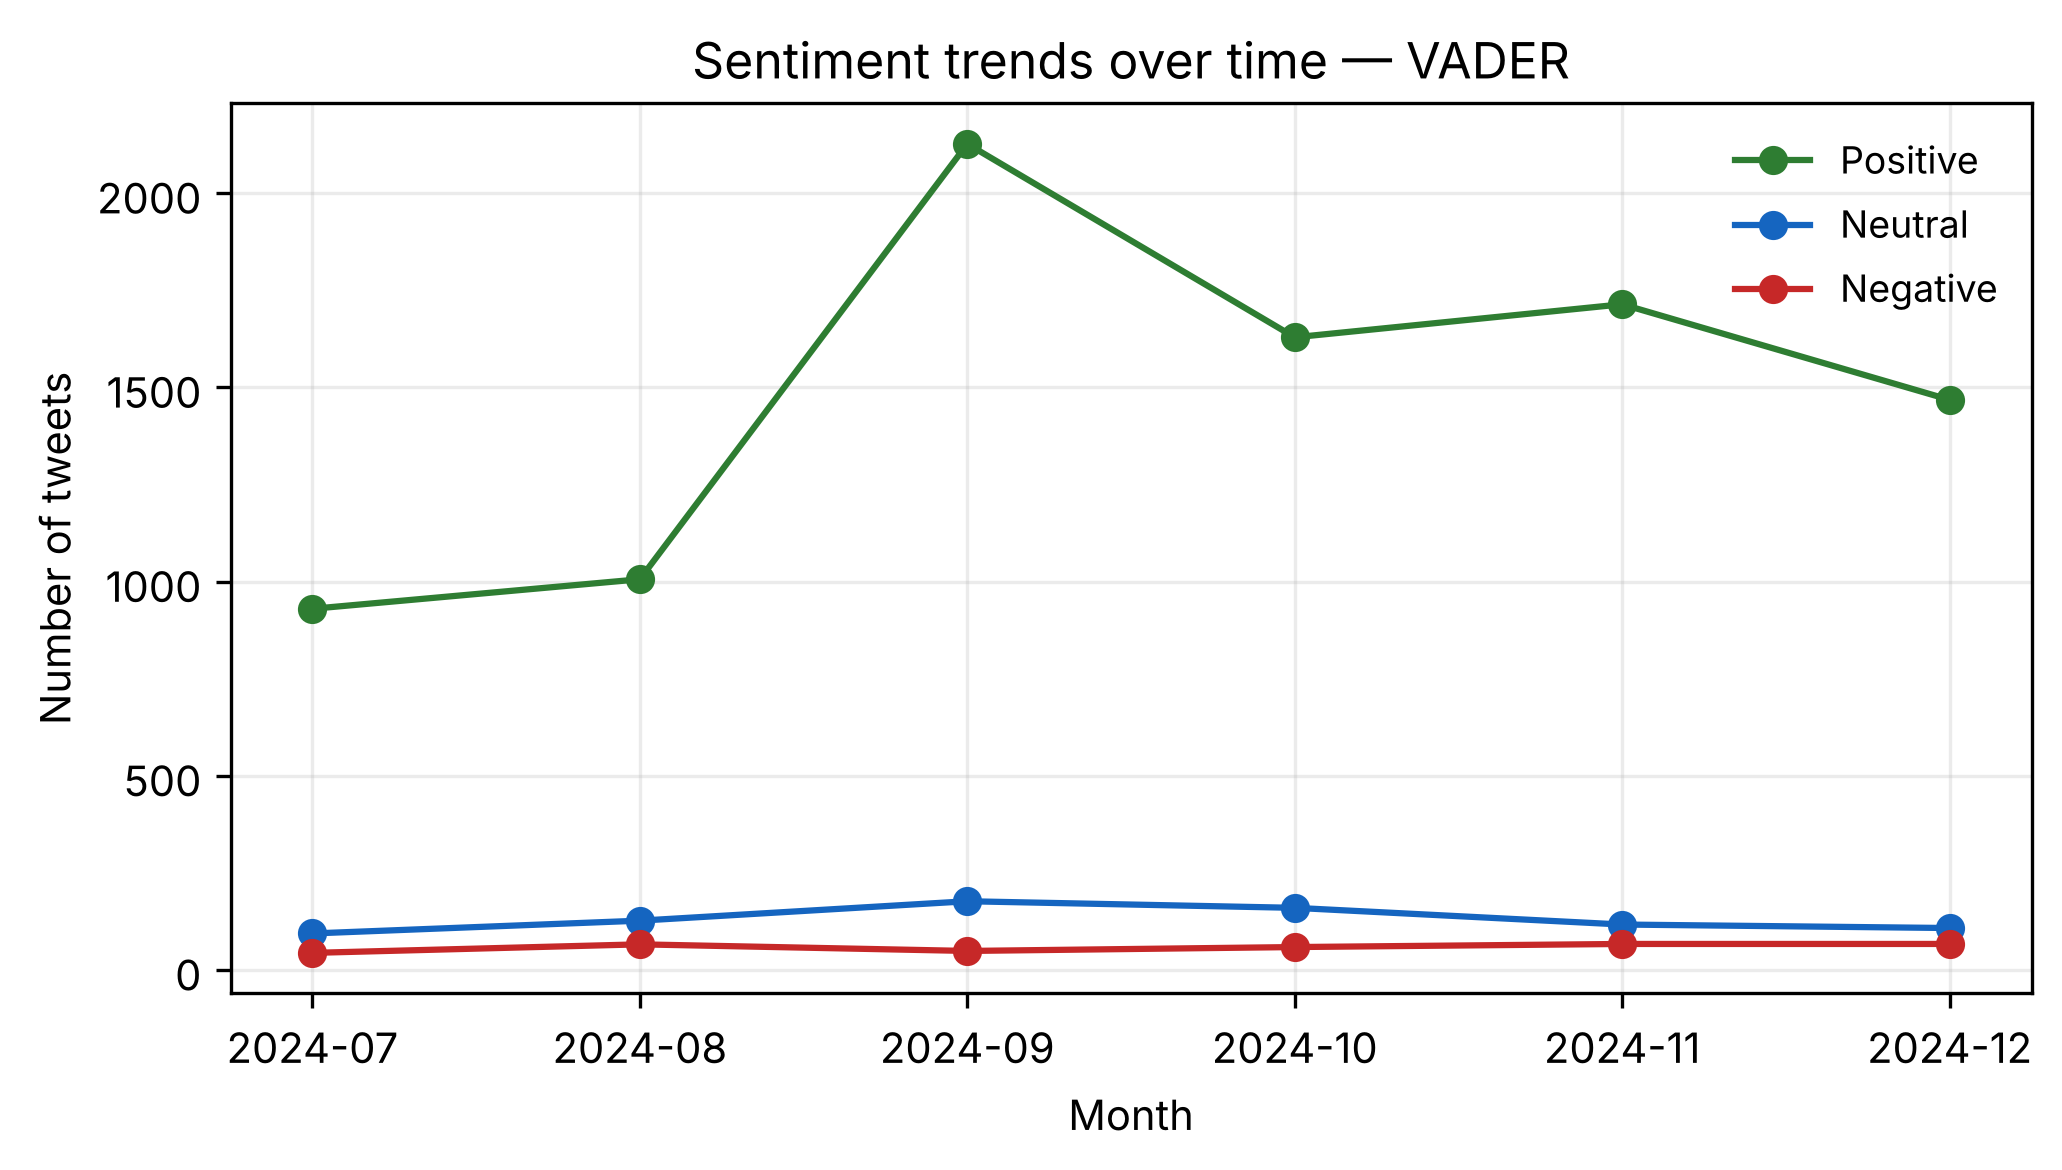

roberta_sentiment,positive,neutral,negative,Total
month,,,,
2024-07,545,481,42,1068
2024-08,658,487,53,1198
2024-09,1564,759,25,2348
2024-10,1235,582,31,1848
2024-11,1263,604,30,1897
2024-12,1128,484,30,1642


In [7]:
tweets["month"] = tweets.created_at.dt.strftime("%Y-%m")
t10 = tweets.groupby(["month", "roberta_sentiment"]).size().unstack(fill_value=0).reindex(columns=ORDER)
t10["Total"] = t10.sum(axis=1)
TABLES["Table 10"] = t10

colours = {"positive": "#2e7d32", "neutral": "#1565c0", "negative": "#c62828"}
for fig_no, (col, name) in zip((2, 3, 4), [("textblob_sentiment", "TextBlob"),
                                          ("roberta_sentiment", "Transformer (RoBERTa)"),
                                          ("vader_sentiment", "VADER")]):
    monthly = tweets.groupby(["month", col]).size().unstack(fill_value=0).reindex(columns=ORDER)
    TABLES[f"Figure {fig_no} data"] = monthly
    fig, ax = plt.subplots(figsize=(7, 4), dpi=300)
    for s in ORDER:
        ax.plot(monthly.index, monthly[s], marker="o", color=colours[s], label=s.capitalize())
    ax.set(xlabel="Month", ylabel="Number of tweets", title=f"Sentiment trends over time — {name}")
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    plt.tight_layout(); plt.savefig(os.path.join(FIGS, f"fig_{fig_no}.png"), dpi=300); plt.show()
t10

## 6. Tables 11–12 — account type

`is_organization` = 1 when the account display name contains, as a whole word, one of: official, news, gov,
ministry, agency, company, corp, ltd, inc, foundation, project, initiative, group, university.

In [8]:
acct = tweets.is_organization.map({0: "Individual", 1: "Organizational"})
t11 = acct.value_counts(normalize=True).mul(100).round(2).to_frame("Percentage (%)")
t12 = (tweets.groupby(acct).roberta_sentiment.value_counts(normalize=True).mul(100).round(2)
       .unstack().reindex(columns=ORDER))
TABLES["Table 11"], TABLES["Table 12"] = t11, t12
display(t11, t12)

,Percentage (%)
is_organization,
Individual,95.69
Organizational,4.31


roberta_sentiment,positive,neutral,negative
is_organization,,,
Individual,64.03,33.78,2.18
Organizational,61.48,38.05,0.46


## 7. Tables 15–16 — geocoding coverage and bias

In [9]:
geo = tweets.is_geocoded.map({1: "Geocoded", 0: "Non-geocoded"})
t15 = geo.value_counts(normalize=True).mul(100).round(2).to_frame("Percentage (%)")
t16 = (tweets.groupby(geo).roberta_sentiment.value_counts(normalize=True).mul(100).round(2)
       .unstack().reindex(columns=ORDER))
TABLES["Table 15"], TABLES["Table 16"] = t15, t16
display(t15, t16)

,Percentage (%)
is_geocoded,
Geocoded,62.06
Non-geocoded,37.94


roberta_sentiment,positive,neutral,negative
is_geocoded,,,
Geocoded,62.82,34.86,2.32
Non-geocoded,65.74,32.50,1.77


## 8. Table 14 — topic–sentiment mapping

In [10]:
topics = pd.read_csv(os.path.join(RESULTS, "lda_topics.csv"))
rows = []
for col, name in MODELS.items():
    ct = pd.crosstab(tweets.topic, tweets[col], normalize="index").mul(100).round(2).reindex(columns=ORDER)
    ct.insert(0, "Model", name)
    rows.append(ct.reset_index())
t14 = (pd.concat(rows).merge(topics[["topic", "interpretation"]], on="topic")
       .sort_values(["topic", "Model"])[["topic", "interpretation", "Model", *ORDER]].reset_index(drop=True))
TABLES["Table 14"] = t14
t14

,topic,interpretation,Model,positive,neutral,negative
0,0,Climate-smart agriculture and resilient practices,TextBlob,62.10,30.94,6.96
1,0,Climate-smart agriculture and resilient practices,Twitter-RoBERTa,59.67,38.18,2.15
2,0,Climate-smart agriculture and resilient practices,VADER,84.76,8.96,6.27
3,1,Technological advancements and scaling in agri...,TextBlob,89.16,7.86,2.98
4,1,Technological advancements and scaling in agri...,Twitter-RoBERTa,82.61,16.35,1.04
5,1,Technological advancements and scaling in agri...,VADER,95.78,2.91,1.32
6,2,Innovations in smart farming and future solutions,TextBlob,82.02,13.47,4.51
7,2,Innovations in smart farming and future solutions,Twitter-RoBERTa,64.82,32.64,2.54
8,2,Innovations in smart farming and future solutions,VADER,90.47,6.89,2.64
9,3,Digital agriculture and industry solutions,TextBlob,74.60,19.69,5.71


## 9. Table 13 and Figure 5 — stored LDA results

LDA (gensim, k = 5, ten passes, `random_state=42`, full vocabulary) was fitted on the tweet text, which is not
redistributed. Its keywords, the coherence sweep (k = 3–10, c_v and c_npmi, both at top-n = 20) and the stability
check are stored in `results/`. Section 10 refits everything from rehydrated text.

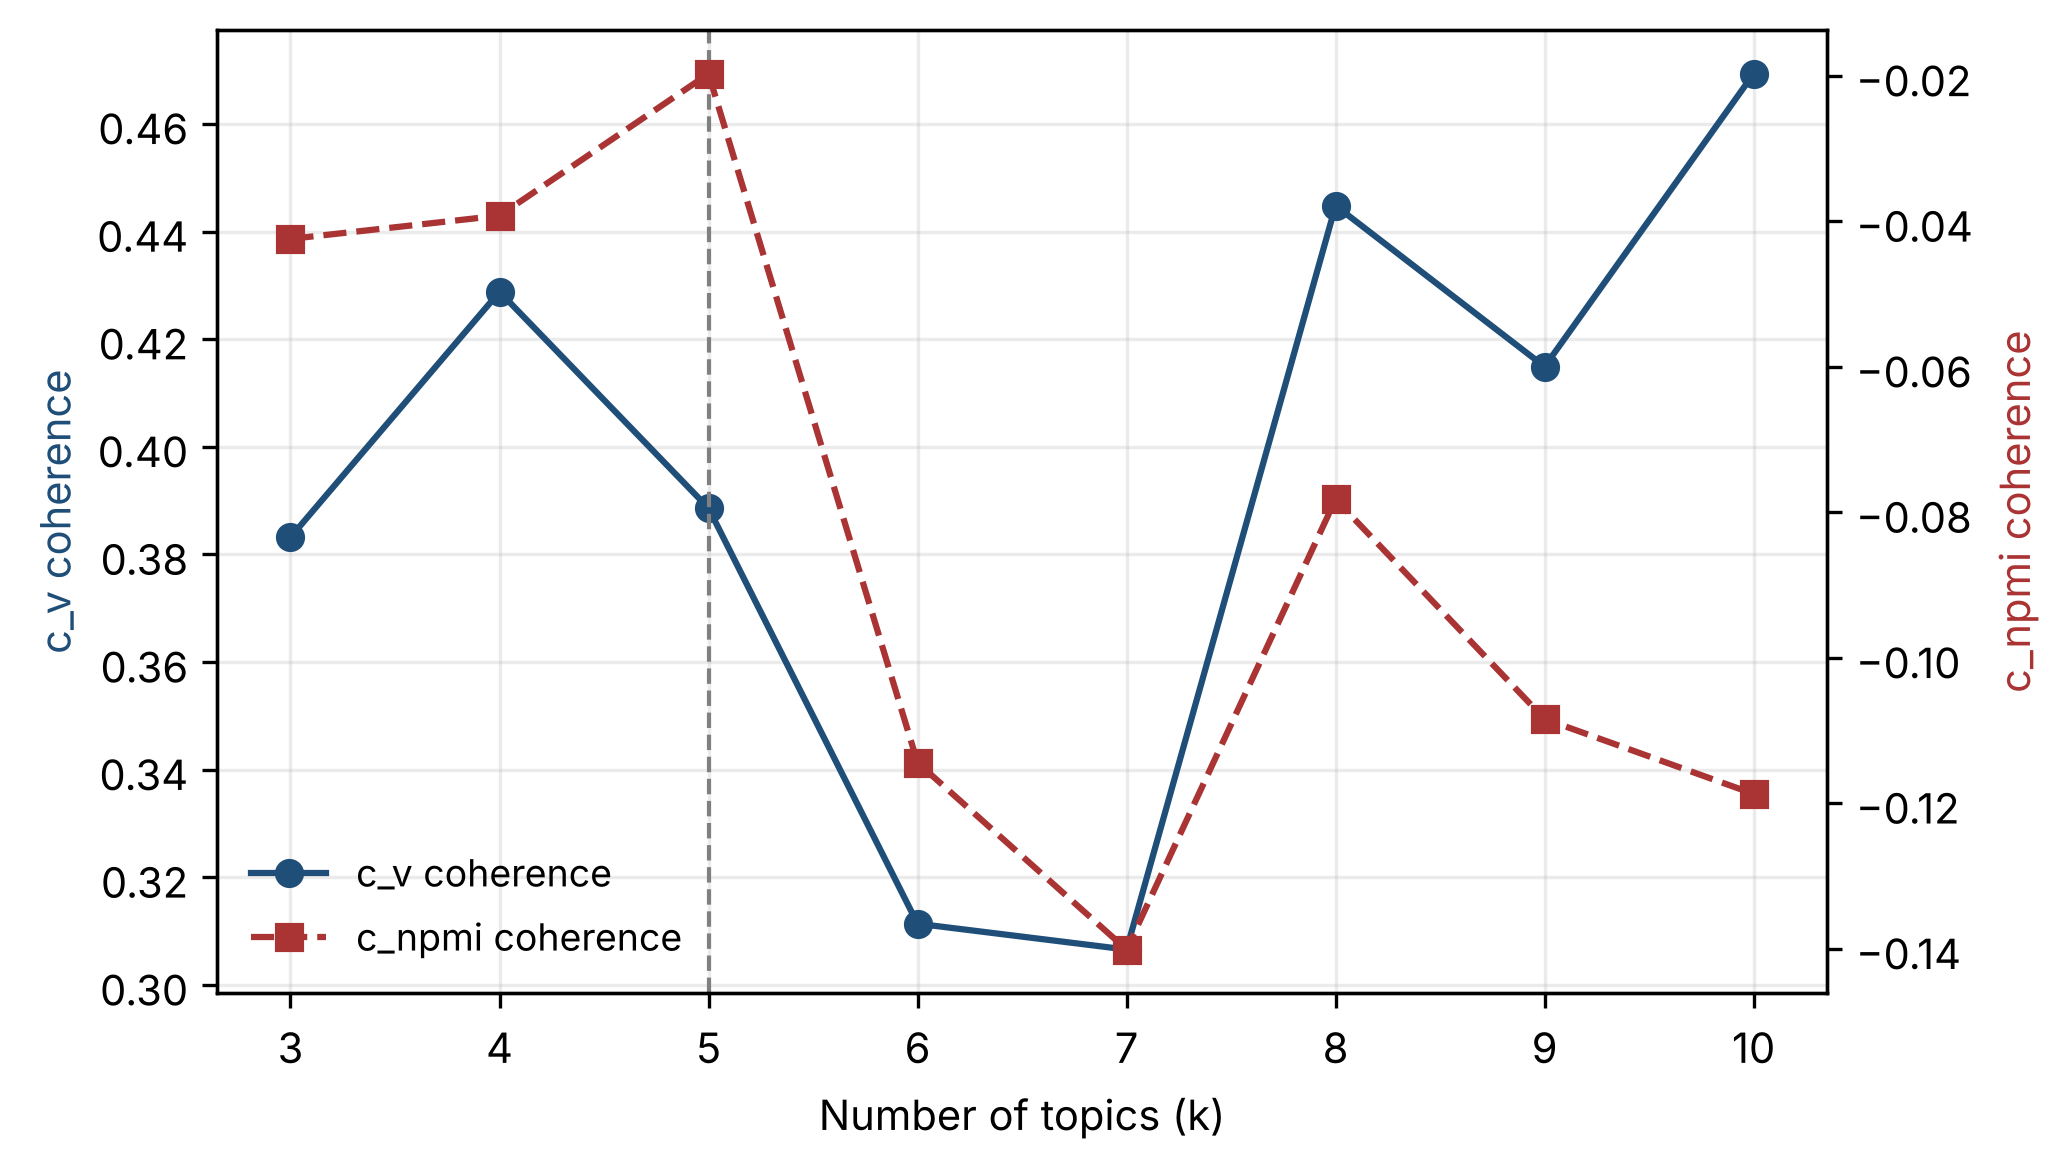

stability: {'k': 5, 'seeds': [42, 1, 2, 3, 4], 'top_n': 10, 'mean_best_match_jaccard': 0.3911, 'coherence_top_n': 20, 'c_v_k5': 0.3886, 'c_npmi_k5': -0.0197, 'lda': {'num_topics': 5, 'passes': 10, 'random_state': 42, 'filter_extremes': False}}


,topic,top_10_keywords,interpretation
0,0,"climate, agriculture, smart, sustainable, farm...",Climate-smart agriculture and resilient practices
1,1,"agriculture, smart, climate, aiccra, ghana, ap...",Technological advancements and scaling in agri...
2,2,"smart, farming, agriculture, sustainable, futu...",Innovations in smart farming and future solutions
3,3,"farming, agriculture, smart, digital, farmers,...",Digital agriculture and industry solutions
4,4,"digital, agriculture, information, smart, new,...",Digital transformation and international initi...


In [11]:
sweep = pd.read_csv(os.path.join(RESULTS, "coherence_sweep.csv"))
stability = json.load(open(os.path.join(RESULTS, "lda_stability.json")))
TABLES["Table 13"], TABLES["Figure 5 data"] = topics, sweep

def plot_coherence(sweep, path):
    fig, ax = plt.subplots(figsize=(7, 4), dpi=300)
    ax.plot(sweep.k, sweep.c_v, "o-", color="#1f4e79", label="c_v coherence")
    ax.set(xlabel="Number of topics (k)", xticks=sweep.k); ax.set_ylabel("c_v coherence", color="#1f4e79")
    ax.axvline(5, ls="--", lw=1, color="grey"); ax.grid(alpha=0.25)
    ax2 = ax.twinx(); ax2.plot(sweep.k, sweep.c_npmi, "s--", color="#a33", label="c_npmi coherence")
    ax2.set_ylabel("c_npmi coherence", color="#a33")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9, frameon=False)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()

plot_coherence(sweep, os.path.join(FIGS, "fig_5.png"))
print("stability:", stability)
display(topics)

## 10. Optional — refit LDA from rehydrated text

Runs only if `data/rehydrated_text.csv` (`tweet_id,text`) exists. Requires `pip install gensim nltk`.

In [12]:
TEXT_FILE = os.path.join(DATA, "rehydrated_text.csv")
HAVE_TEXT = os.path.exists(TEXT_FILE)
print("rehydrated text found" if HAVE_TEXT else "no rehydrated text -> sections 10-11 skipped")

if HAVE_TEXT:
    import gensim, nltk
    from gensim import corpora
    from gensim.models import LdaModel
    from gensim.models.coherencemodel import CoherenceModel
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

    text = pd.read_csv(TEXT_FILE, dtype={"tweet_id": str})
    corpus_df = tweets[["tweet_id"]].merge(text, on="tweet_id", how="inner")
    print(f"rehydrated {len(corpus_df):,} of {len(tweets):,} tweets")

    CUSTOM_STOP = {"https", "amp", "let", "read", "every", "full", "great", "key", "public", "services",
                   "project", "join", "like", "register", "mission", "data"}
    STOP = set(stopwords.words("english")) | CUSTOM_STOP
    texts = [[w for w in gensim.utils.simple_preprocess(str(t)) if w not in STOP and len(w) > 2]
             for t in corpus_df.text]
    dictionary = corpora.Dictionary(texts)
    bow = [dictionary.doc2bow(t) for t in texts]

    def fit(k, seed=42):
        return LdaModel(corpus=bow, id2word=dictionary, num_topics=k, random_state=seed, passes=10)
    def coherence(model, kind):
        return CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence=kind, topn=20).get_coherence()

    lda5 = fit(5)
    for i in range(5):
        print(f"Topic {i}:", ", ".join(w for w, _ in lda5.show_topic(i, topn=10)))
    refit = pd.DataFrame([{"k": k, "c_v": round(coherence(m, "c_v"), 4), "c_npmi": round(coherence(m, "c_npmi"), 4)}
                          for k in range(3, 11) for m in [fit(k)]])
    runs = [[set(w for w, _ in fit(5, s).show_topic(i, topn=10)) for i in range(5)] for s in (42, 1, 2, 3, 4)]
    jac = np.mean([max(len(a & b) / len(a | b) for b in runs[j])
                   for i, j in itertools.combinations(range(5), 2) for a in runs[i]])
    print(f"mean best-match Jaccard (k=5, 5 seeds): {jac:.4f}")
    plot_coherence(refit, os.path.join(FIGS, "fig_5_refit.png"))
    display(refit)

no rehydrated text -> sections 10-11 skipped


## 11. Optional — re-score sentiment from rehydrated text

Requires `pip install textblob vaderSentiment transformers torch`. A GPU runtime is recommended.

In [13]:
if HAVE_TEXT:
    from textblob import TextBlob
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from scipy.special import softmax

    vader = SentimentIntensityAnalyzer()
    tok = AutoTokenizer.from_pretrained(TRANSFORMER)
    mdl = AutoModelForSequenceClassification.from_pretrained(TRANSFORMER)
    LABELS = ["negative", "neutral", "positive"]          # label order of the cardiffnlp model

    def textblob_label(t):
        p = TextBlob(str(t)).sentiment.polarity
        return "positive" if p > 0 else "negative" if p < 0 else "neutral"
    def vader_label(t):
        c = vader.polarity_scores(str(t))["compound"]
        return "positive" if c >= 0.05 else "negative" if c <= -0.05 else "neutral"
    def roberta(t):
        enc = tok(str(t), return_tensors="pt", truncation=True, max_length=512)
        p = softmax(mdl(**enc).logits.detach().numpy()[0])
        return LABELS[int(p.argmax())], float(p.max())

    rescored = corpus_df.copy()
    rescored["textblob_sentiment"] = rescored.text.map(textblob_label)
    rescored["vader_sentiment"] = rescored.text.map(vader_label)
    rescored[["roberta_sentiment", "roberta_confidence"]] = rescored.text.map(roberta).tolist()
    cmp = rescored.merge(tweets, on="tweet_id", suffixes=("_new", ""))
    for col in MODELS:
        print(f"{MODELS[col]:16s} agreement with published labels: {(cmp[col + '_new'] == cmp[col]).mean():.4f}")

## 12. Export

In [14]:
path = os.path.join(RESULTS, "replicated_tables.xlsx")
with pd.ExcelWriter(path) as xl:
    for name, df in TABLES.items():
        df.to_excel(xl, sheet_name=name[:31])
print(f"{len(TABLES)} tables written to {path}; figures in {FIGS}")

19 tables written to ../results/replicated_tables.xlsx; figures in ../results/figures
